# Projet 5

**Question** : peut-on détecter des attaques inconnues sans exemples de ces attaques à l'entraînement ?

**Approche** : apprendre uniquement le trafic **normal**, puis signaler ce qui s'en écarte.

**Hypothèses**:
- **H1** : les détecteurs ont des compromis différents entre détection et faux positifs.
- **H2** : contaminer l'entraînement avec des attaques dégrade la détection.
- **H3** : les détecteurs d'anomalies sont moins précis qu'un modèle supervisé, mais meilleurs sur certaines attaques inconnues.

# Phase 1 - Compréhension du dataset et EDA ciblée

## 1.1 Configuration et parametres

In [28]:
import os
import time
import warnings
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, PrecisionRecallDisplay, RocCurveDisplay,
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

#Paramètres
RANDOM_STATE = 42
DATA_DIR = os.environ.get("UNSW_DATA_DIR", "../data/raw")
TRAIN_FILE = "UNSW_NB15_training-set.csv"
TEST_FILE = "UNSW_NB15_testing-set.csv"
OUT_DIR = "results"                    # tableaux et figures pour le rapport

VAL_SIZE = 0.2                         # part du train gardée pour la validation
N_FIT = 2_000 if FAST_MODE else 20_000 # flux normaux d'entraînement (coût de LOF / OC-SVM)
TARGET_FPR = 0.05                      # budget de fausses alertes pour fixer le seuil
FPR_LEVELS = [0.01, 0.02, 0.05, 0.10]  # budgets testés
UNKNOWN_FAMILIES = ["Reconnaissance", "Backdoor", "Shellcode", "Worms"]  # familles « inconnues » (Exp. 3)
CLIP_QUANTILE = 0.99                   # écrêtage des valeurs extrêmes

os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(RANDOM_STATE)

def save_fig(fig, name):
    fig.savefig(os.path.join(OUT_DIR, f"{name}.png"), bbox_inches="tight")

def save_table(df, name):
    df.to_csv(os.path.join(OUT_DIR, f"{name}.csv"))

pd.Series({"Python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
       "matplotlib": matplotlib.__version__, "seaborn": sns.__version__}, name="version").to_frame()


,version
Python,3.13.5
numpy,2.5.3
pandas,3.0.6
scikit-learn,1.9.1
scipy,1.18.1
matplotlib,3.11.2
seaborn,0.13.2


## 1.2 Chargement

UNSW-NB15 : un flux réseau par ligne, 42 variables, `label` (0 normal / 1 attaque) et `attack_cat` (famille).

In [14]:
train_df = pd.read_csv(os.path.join(DATA_DIR, TRAIN_FILE))
test_df = pd.read_csv(os.path.join(DATA_DIR, TEST_FILE))

for df in (train_df, test_df):
    df["attack_cat"] = df["attack_cat"].astype(str).str.strip()

FEATURES = [c for c in train_df.columns if c not in ("id", "attack_cat", "label")]
CAT_COLS = ["proto", "service", "state"]

print("Valeurs manquantes :", int(train_df.isna().sum().sum()), "/", int(test_df.isna().sum().sum()))

Valeurs manquantes : 0 / 0


## 1.3 EDA ciblée

On regarde si les familles inconnues ont assez de flux de test et on retire les doublons du **train**


Part de flux normaux dupliqués dans le train : 7.3%


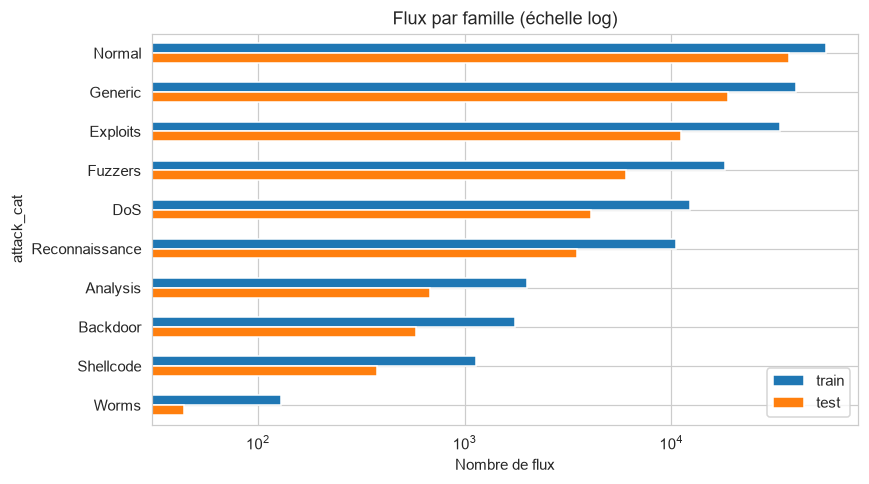

,train,test,inconnue (Exp. 3)
attack_cat,,,
Normal,56000,37000,False
Generic,40000,18871,False
Exploits,33393,11132,False
Fuzzers,18184,6062,False
DoS,12264,4089,False
Reconnaissance,10491,3496,True
Analysis,2000,677,False
Backdoor,1746,583,True
Shellcode,1133,378,True


In [29]:
fam = pd.DataFrame({
    "train": train_df["attack_cat"].value_counts(),
    "test": test_df["attack_cat"].value_counts(),
}).fillna(0).astype(int).sort_values("train", ascending=False) #on compte les lignes et 0 si une famille est absente
fam["inconnue (Exp. 3)"] = fam.index.isin(UNKNOWN_FAMILIES) #True si la famille est notée comme inconnues précédemment

dup_normal = train_df[train_df["label"] == 0].duplicated(subset=FEATURES).mean()
print(f"Part de flux normaux dupliqués dans le train : {dup_normal:.1%}")

fig, ax = plt.subplots(figsize=(8, 4.5))
fam[["train", "test"]].plot(kind="barh", logx=True, ax=ax)
ax.invert_yaxis()
ax.set_title("Flux par famille (échelle log)")
ax.set_xlabel("Nombre de flux")
plt.tight_layout(); save_fig(fig, "eda_familles"); plt.show()
fam

Sur le **train** on compare les attaques et normales pour différencier leurs comportement, si décalage -> on peut utiliser un détecteur sinon difficile avec un détecteur

Log appliqué pour visualiser correctement

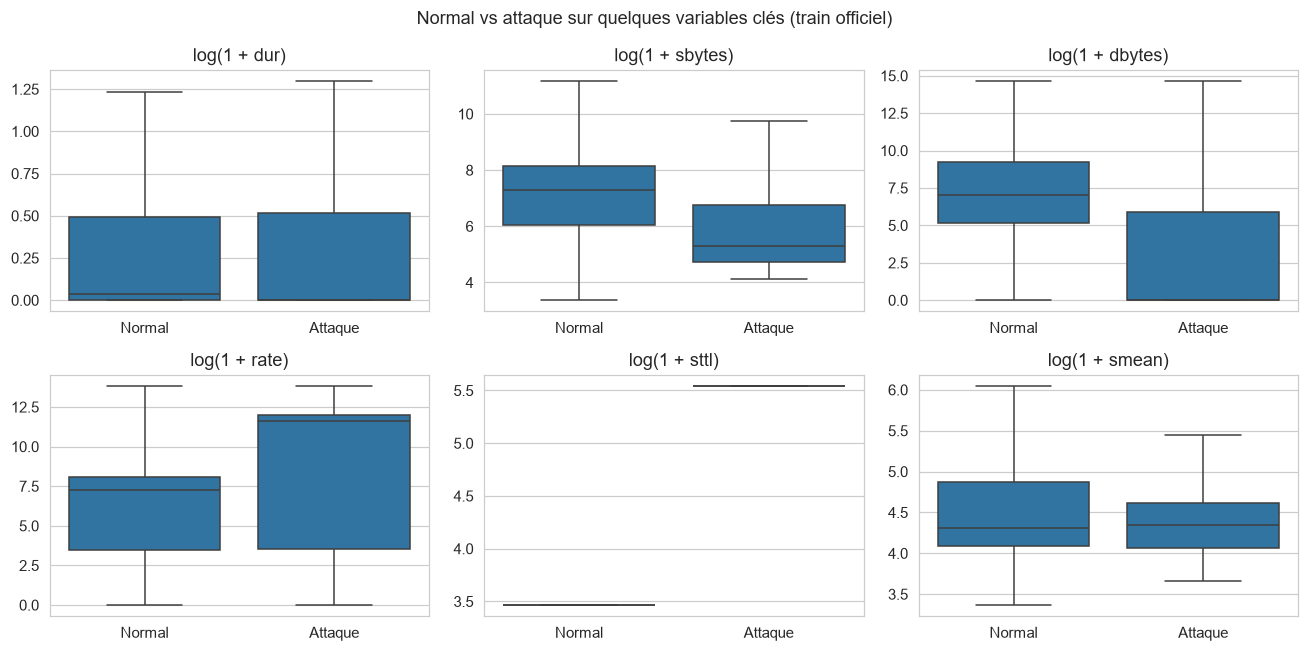

In [17]:
KEY_VARS = [c for c in ["dur", "sbytes", "dbytes", "rate", "sttl", "smean"] if c in FEATURES]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), KEY_VARS):
    sns.boxplot(data=train_df.assign(classe=train_df["label"].map({0: "Normal", 1: "Attaque"})),
                x="classe", y=np.log1p(train_df[col]), ax=ax, showfliers=False)
    ax.set_title(f"log(1 + {col})"); ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("Normal vs attaque sur quelques variables clés (train officiel)")
plt.tight_layout(); save_fig(fig, "eda_variables_cles"); plt.show()

## 1.4 Conclusions

- Trafic normal abondant -> on apprend sur un échantillon de `N_FIT` flux.
- Familles rares (Worms, Shellcode) -> taux de détection peu fiables.
- Doublons -> retirés de l'entraînement, gardés en validation et test.
- Distributions très asymétriques -> transformation log.

# Phase 2 - Préparation, pipeline et baseline

## 2.1 Découpage
80% pour l'entrainement et 20% pour la validation en gardant la même proportions de chaque famille

Jeu d'entraînement 20000 de flux normaux


In [18]:
train_part, val_df = train_test_split(
    train_df, test_size=VAL_SIZE, stratify=train_df["attack_cat"], random_state=RANDOM_STATE)

normal_pool = train_part[train_part["label"] == 0].drop_duplicates(subset=FEATURES)
attack_pool = train_part[train_part["label"] == 1]

X_val, y_val = val_df[FEATURES], val_df["label"].to_numpy()
X_test, y_test = test_df[FEATURES], test_df["label"].to_numpy()
val_normal = y_val == 0
X_val_normal = X_val[val_normal]

N_FIT = min(N_FIT, len(normal_pool))
X_fit = normal_pool.sample(n=N_FIT, random_state=RANDOM_STATE)[FEATURES]

num_cols = [c for c in FEATURES if c not in CAT_COLS]
CONT_COLS = [c for c in num_cols if normal_pool[c].nunique() > 50]
DISC_COLS = [c for c in num_cols if c not in CONT_COLS]

splits = pd.DataFrame({
    "flux": [len(normal_pool), len(attack_pool), N_FIT, len(val_df), len(test_df)],
    "dont attaques": [0, len(attack_pool), 0, int(y_val.sum()), int(y_test.sum())],
}, index=["Pool normal (sans doublons)", "Pool attaques", "Entraînement détecteurs (N_FIT)",
          "Validation", "Test officiel"])
save_table(splits, "decoupage")
splits

,flux,dont attaques
Pool normal (sans doublons),41836,0
Pool attaques,95472,95472
Entraînement détecteurs (N_FIT),20000,0
Validation,35069,23869
Test officiel,82332,45332


**Contrôles de non-fuite**

Contrôle à chaque exécution l'absence de fuite de données

In [19]:
assert (train_df.loc[X_fit.index, "label"] == 0).all(), "Une attaque s'est glissée dans l'entraînement"
assert X_fit.index.isin(train_part.index).all(), "L'entraînement doit venir des 80 % du train officiel"
assert not X_fit.index.isin(val_df.index).any(), "Recouvrement entre entraînement et validation"
assert not X_fit.duplicated().any(), "Il reste des doublons dans l'entraînement"
print("Contrôles réussis : entraînement 100 % normal, sans doublon, disjoint de la validation.")
print(f"Validation : {int((y_val == 0).sum())} flux normaux, {int(y_val.sum())} attaques")
print(f"Test officiel (fichier séparé) : {int((y_test == 0).sum())} flux normaux, {int(y_test.sum())} attaques")

Contrôles réussis : entraînement 100 % normal, sans doublon, disjoint de la validation.
Validation : 11200 flux normaux, 23869 attaques
Test officiel (fichier séparé) : 37000 flux normaux, 45332 attaques


## 2.2 Pipeline de prétraitement

Appris sur l'entraînement seulement, puis appliqué tel quel à la validation et au test.

| Variables | Traitement |
|---|---|
| Continues (> 50 valeurs distinctes) | Écrêtage au 99e percentile → `log1p` → standardisation |
| Discrètes | Standardisation |
| Catégorielles | One-hot des 5 modalités les plus fréquentes + « rare » |

In [20]:
class QuantileClipper(BaseEstimator, TransformerMixin): #plafonne les valeurs extremes
    def __init__(self, upper_quantile=0.99):
        self.upper_quantile = upper_quantile
    def fit(self, X, y=None):
        self.upper_ = np.quantile(np.asarray(X, dtype=float), self.upper_quantile, axis=0)
        return self
    def transform(self, X):
        return np.minimum(np.asarray(X, dtype=float), self.upper_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def log1p_pos(X): #Compresse les grandes valeurs
    return np.log1p(np.clip(X, 0, None))


def build_preprocessor(cont_cols, disc_cols, cat_cols): # en fonction du groupe de colonnes, on l'envoie dans un traitement adapté
    cont_pipe = Pipeline([
        ("clip", QuantileClipper(CLIP_QUANTILE)),
        ("log", FunctionTransformer(log1p_pos, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer([
        ("cont", cont_pipe, cont_cols),
        ("disc", StandardScaler(), disc_cols),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", max_categories=6), cat_cols),
    ], sparse_threshold=0)


def make_pipeline(model, cols=None):
    cont, disc, cat = cols or (CONT_COLS, DISC_COLS, CAT_COLS)
    return Pipeline([("prep", build_preprocessor(cont, disc, cat)), ("model", model)])

**Vérification** : moyenne 0 et écart-type 1 sur l'entraînement uniquement (pas de fuite).

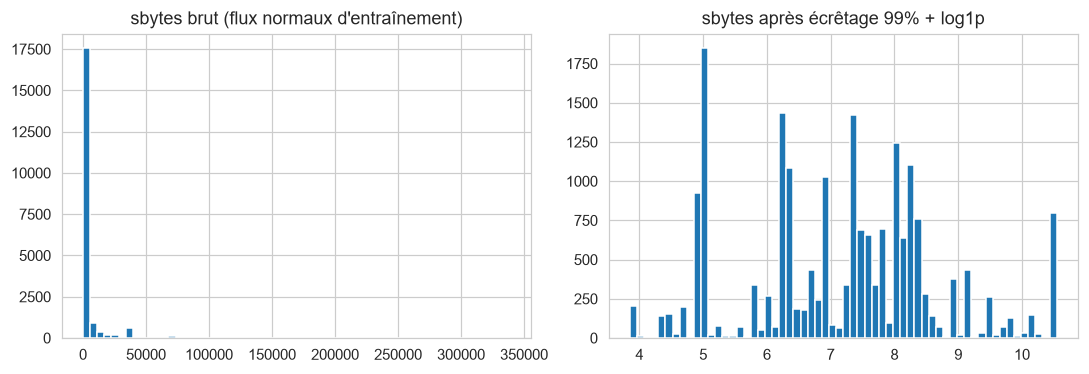

Dimension après prétraitement : 57 colonnes (22 continues, 17 discrètes, 18 one-hot)
Moyenne et écart-type des variables continues transformées :


,moyenne,écart-type
Entraînement (X_fit),-0.000,1.000
Validation,-0.348,1.271
Test,-0.292,1.262


In [23]:
col = "sbytes"
clip = QuantileClipper(CLIP_QUANTILE).fit(X_fit[[col]])
after = log1p_pos(clip.transform(X_fit[[col]])).ravel()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(X_fit[col], bins=60)
axes[0].set_title(f"{col} brut (flux normaux d'entraînement)")
axes[1].hist(after, bins=60)
axes[1].set_title(f"{col} après écrêtage {CLIP_QUANTILE:.0%} + log1p")
plt.tight_layout(); save_fig(fig, "phase2_effet_pretraitement"); plt.show()

prep = build_preprocessor(CONT_COLS, DISC_COLS, CAT_COLS).fit(X_fit)
names = prep.get_feature_names_out()
n_cont = len(CONT_COLS)
check = pd.DataFrame({
    jeu: {"moyenne": prep.transform(X)[:, :n_cont].mean(), "écart-type": prep.transform(X)[:, :n_cont].std()}
    for jeu, X in [("Entraînement (X_fit)", X_fit), ("Validation", X_val), ("Test", X_test)]
}).T
print(f"Dimension après prétraitement : {len(names)} colonnes "
      f"({len(CONT_COLS)} continues, {len(DISC_COLS)} discrètes, {len(names) - len(CONT_COLS) - len(DISC_COLS)} one-hot)")
print("Moyenne et écart-type des variables continues transformées :")
check.style.format("{:.3f}")

## 2.3 Baseline et outils communs

**Baseline z-score** : score = écart moyen au trafic normal, en écarts-types. Modèle minimal à battre.

**Seuil** : 95e percentile des scores des flux **normaux** de validation (FPR visé 5 %). Aucune attaque utilisée.

**Métriques** : précision, rappel, F1, Macro-F1, FPR, ROC-AUC, PR-AUC (pas d'accuracy seule).

In [24]:
class ZScoreBaseline(BaseEstimator):
    #Baseline : écart absolu moyen (en écarts-types) au trafic normal d'entraînement.
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.mu_, self.sd_ = X.mean(axis=0), X.std(axis=0)
        self.sd_[self.sd_ == 0] = 1.0   # évite une division par zéro pour une variable constante
        return self

    def score_samples(self, X):
        # Convention scikit-learn : score élevé = normal. On renvoie donc l'opposé de l'écart moyen.
        X = np.asarray(X, dtype=float)
        return -np.abs((X - self.mu_) / self.sd_).mean(axis=1)


def anomaly_score(pipe, X):
    #Plus le score est élevé, plus le flux est anormal.
    return -pipe.score_samples(X)


def threshold_from_normals(scores_normal, target_fpr=TARGET_FPR):
    #Seuil tel qu'une part target_fpr des flux normaux le dépasse.
    #Exemple : target_fpr = 5 % -> 95e percentile des scores normaux de validation.
    #Aucune attaque n'est utilisée (cohérent avec le scénario étudié).
    return np.quantile(scores_normal, 1 - target_fpr)


def detection_metrics(y, scores, thr):
    pred = (scores >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "Précision": precision_score(y, pred, zero_division=0),
        "Rappel": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "Macro-F1": f1_score(y, pred, average="macro", zero_division=0),
        "FPR": fp / (fp + tn) if (fp + tn) else np.nan,
        "ROC-AUC": roc_auc_score(y, scores),
        "PR-AUC": average_precision_score(y, scores),
        "FP": int(fp), "FN": int(fn),
    }


PCT_COLS = ["Précision", "Rappel", "F1", "Macro-F1", "FPR", "ROC-AUC", "PR-AUC"]

def fmt(df):
    cols = [c for c in PCT_COLS if c in df.columns]
    return df.style.format({c: "{:.1%}" for c in cols}, precision=2)

## 2.4 Évaluation de la baseline

In [25]:
baseline = Pipeline([
    ("prep", build_preprocessor(CONT_COLS, DISC_COLS, CAT_COLS)),
    ("model", ZScoreBaseline()),
])
t0 = time.perf_counter()
baseline.fit(X_fit)
t_fit = time.perf_counter() - t0

s_val_bl, s_test_bl = anomaly_score(baseline, X_val), anomaly_score(baseline, X_test)
thr_bl = threshold_from_normals(s_val_bl[val_normal])

bl_results = pd.DataFrame({
    "Validation": detection_metrics(y_val, s_val_bl, thr_bl),
    "Test officiel": detection_metrics(y_test, s_test_bl, thr_bl),
}).T
save_table(bl_results, "phase2_baseline")
print(f"Baseline entraînée en {t_fit:.2f} s sur {len(X_fit)} flux normaux | seuil = {thr_bl:.3f}")
print(f"Proportion d'attaques (PR-AUC d'un modèle aléatoire) : validation {y_val.mean():.1%}, test {y_test.mean():.1%}")
fmt(bl_results)

Baseline entraînée en 0.26 s sur 20000 flux normaux | seuil = 1.356
Proportion d'attaques (PR-AUC d'un modèle aléatoire) : validation 68.1%, test 55.1%


,Précision,Rappel,F1,Macro-F1,FPR,ROC-AUC,PR-AUC,FP,FN
Validation,96.0%,55.7%,70.5%,68.1%,5.0%,86.1%,92.9%,561.00,10571.00
Test officiel,93.9%,43.1%,59.1%,65.8%,3.5%,80.5%,86.4%,1277.00,25805.00


**Distribution des scores, courbes ROC / PR, rappel selon le budget de FPR**

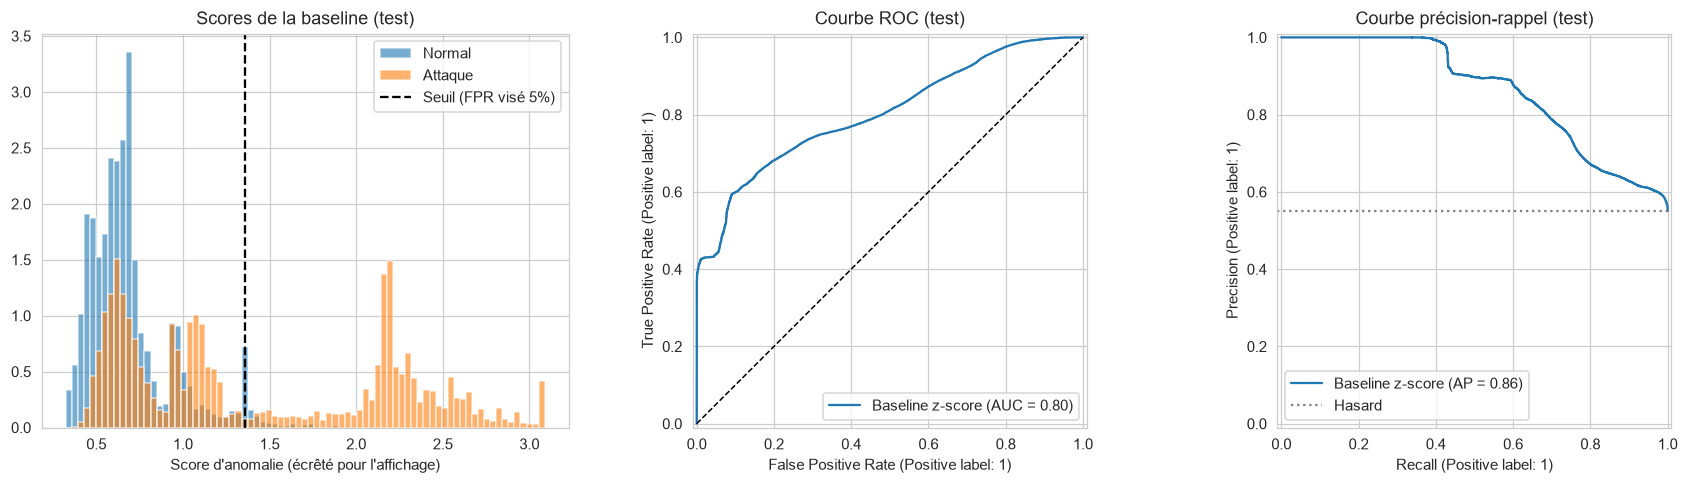

,FPR obtenu (test),Rappel (test),Précision (test)
FPR visé (validation),,,
1%,0.9%,42.0%,98.3%
2%,2.2%,43.0%,96.0%
5%,3.5%,43.1%,93.9%
10%,11.3%,60.9%,86.8%


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
lo, hi = np.quantile(s_test_bl, [0.001, 0.995])
bins = np.linspace(lo, hi, 80)
sc = np.clip(s_test_bl, lo, hi)
axes[0].hist(sc[y_test == 0], bins=bins, alpha=0.6, density=True, label="Normal")
axes[0].hist(sc[y_test == 1], bins=bins, alpha=0.6, density=True, label="Attaque")
axes[0].axvline(np.clip(thr_bl, lo, hi), color="black", ls="--", label=f"Seuil (FPR visé {TARGET_FPR:.0%})")
axes[0].set_title("Scores de la baseline (test)"); axes[0].set_xlabel("Score d'anomalie (écrêté pour l'affichage)")
axes[0].legend()
RocCurveDisplay.from_predictions(y_test, s_test_bl, name="Baseline z-score", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_title("Courbe ROC (test)")
PrecisionRecallDisplay.from_predictions(y_test, s_test_bl, name="Baseline z-score", ax=axes[2])
axes[2].axhline(y_test.mean(), color="grey", ls=":", label="Hasard"); axes[2].legend()
axes[2].set_title("Courbe précision-rappel (test)")
plt.tight_layout(); save_fig(fig, "phase2_baseline_scores"); plt.show()

rows = []
for f in FPR_LEVELS:
    m = detection_metrics(y_test, s_test_bl, threshold_from_normals(s_val_bl[val_normal], f))
    rows.append({"FPR visé (validation)": f"{f:.0%}", "FPR obtenu (test)": m["FPR"],
                 "Rappel (test)": m["Rappel"], "Précision (test)": m["Précision"]})
bl_tradeoff = pd.DataFrame(rows).set_index("FPR visé (validation)")
save_table(bl_tradeoff, "phase2_baseline_compromis")
bl_tradeoff.style.format("{:.1%}")

**Détection par famille** (validation ; *Normal* = FPR)

In [27]:
pred_val = s_val_bl >= thr_bl
fam_bl = (pd.Series(pred_val, index=val_df.index).groupby(val_df["attack_cat"])
          .agg(taux_de_détection="mean", flux="count")
          .sort_values("taux_de_détection", ascending=False))
save_table(fam_bl, "phase2_baseline_par_famille")
fam_bl.style.format({"taux_de_détection": "{:.1%}"})

,taux_de_détection,flux
attack_cat,,
Generic,93.3%,8000
Backdoor,82.2%,349
DoS,76.6%,2453
Analysis,74.8%,400
Exploits,39.2%,6679
Reconnaissance,17.4%,2098
Fuzzers,10.8%,3637
Normal,5.0%,11200
Shellcode,0.0%,227
